<a href="https://colab.research.google.com/github/Sulieman25/Jordanian-PC-Builder---DS493/blob/main/PC-Builder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jordanian PC Builder — Phase 2 training notebook

**One notebook, in execution order:** inspect real Jordanian component prices → extract PC-compatibility articles → build a **document-level 90/10 holdout** → measure the base model → **continued pretraining (CPT)** → create reviewed/source-backed Q&A pairs → **answer-only SFT** → display **the same five test questions across base, CPT and SFT**.

This is a replacement for `Test1.ipynb`, not a full PC-building application. It intentionally stops after training, simple prompts, and saving results. It does **not** claim that trained text alone can enforce part compatibility or provide live prices.

**Files to supply:**

- `components.csv` — your Oriental Store export (the original 2,250-row CSV is supported).
- `articles/` — the actual technical article PDFs shown in your screenshot. **These PDFs were not attached to the chat**, so you must copy them here; the Phase 1/2 assignment PDFs are **not** compatibility references.
- `test_questions.csv` — optional at first, but required for the official 30-question evaluation later. Columns: `id,question,expected_answer,source,difficulty`.
- `sft_verified.jsonl` — optional, recommended: human-checked Q&As based on the articles, one JSON object per line with `question`, `answer`, and ideally `source`.

The catalogue's `price_jod` column is a **historical listing snapshot**, not a guarantee of current price, stock, or compatibility. Check training/redistribution permissions for third-party articles before using them.

## 1. Install dependencies


In [1]:
%pip -q install "transformers>=4.50,<5" "accelerate>=1,<2" "pymupdf>=1.24" "pandas>=2" "matplotlib>=3.7" "sentencepiece>=0.2"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Configuration and Data
Change only these values when switching between GPT-2, SmolLM2, another standard Hugging Face **LM**, a different folder, or training settings.

###2.1 Calling the data

In [2]:
!pip install gitpython -q

import git
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Read the token from the shared text file
# IMPORTANT: Update this path to exactly where the file is in your shared Drive
token_path = Path('/content/drive/MyDrive/Tokens/github-token.txt')
shared_token = token_path.read_text().strip()

# 3. Define the repository details and inject the token
repo_url = f"https://{shared_token}@github.com/Sulieman25/Jordanian-PC-Builder---DS493.git"
base_dir = Path("/content")
repo_name = "Jordanian-PC-Builder---DS493"
repo_path = base_dir / repo_name

# 4. Clone the repo
if not repo_path.exists():
    print(f"Cloning {repo_name}...")
    # GitPython requires string conversion for the destination path
    git.Repo.clone_from(repo_url, str(repo_path))
else:
    print(f"{repo_name} is already cloned.")

# 5. Assign paths to variables for your workflow using pathlib (/)
DATA_PATH = repo_path / "data"
CPT_DATA_PATH = DATA_PATH / "cpt"
SRC_PATH = repo_path / "src"
RESULTS_PATH = repo_path / "results"
TESTS_PATH = repo_path / "tests"
CSV_PATH = DATA_PATH / "components.csv"
TEST_CSV_PATH = TESTS_PATH / "test_questions.csv"
VERIFIED_QA_PATH = DATA_PATH / "sft_verified.jsonl"

# 6. Map the variables needed for the rest of the training notebook
OUTPUT_DIR = RESULTS_PATH

ARTICLE_DIR = DATA_PATH

USE_DRIVE = False # Switched to False because we are using the cloned GitHub repo now

# 7. Automatically discover all PDF articles
ARTICLE_PATHS = sorted(DATA_PATH.glob("*.pdf"))

# 8. Verify files
assert DATA_PATH.exists(), f"Folder not found: {DATA_PATH}"
assert CSV_PATH.exists(), f"CSV not found: {CSV_PATH}"

# 9. Print summaries
print("Repository cloned and paths assigned successfully.")
print(f"Components CSV: {CSV_PATH.name}")
print(f"Articles found: {len(ARTICLE_PATHS)}")

for article in ARTICLE_PATHS:
    print(article.name)

if len(ARTICLE_PATHS) != 15:
    print("Warning: Expected 15 PDF articles.")

Mounted at /content/drive
Cloning Jordanian-PC-Builder---DS493...
Repository cloned and paths assigned successfully.
Components CSV: components.csv
Articles found: 14
Best Graphics Cards for Gaming in 2026 _ Tom_s Hardware.pdf
Best cheap gaming PC deals _ PC Gamer.pdf
Best gaming PC builds_ Shop all our recommended system builds as we ride out the RAMpocalypse _ PC Gamer.pdf
Best gaming PCs in 2026_ We_ve tested the best current-gen gaming PCs and these are our picks _ PC Gamer.pdf
Buying PC Components_ Compatibility, Specs and Common Pitfalls.pdf
Choose a Processor - OpenClassrooms.pdf
Design Your Dream PC with CORSAIR _ CORSAIR.pdf
How do I check if parts go together_ PC Compatibility Guide.pdf
How to Build a PC (2025)_ Hardware Suggestions, Instructions, and More _ WIRED.pdf
How to Choose a Motherboard and Compatible PC Parts Guide.pdf
How to Choose a PC Case for Your Build_ Steps & Checklist.pdf
How to Choose a Power Supply for Your PC_ Steps & Checklist.pdf
How to build a PC in 20

In [24]:
import ipywidgets as widgets
from IPython.display import display

# Define your team's details
teammates = {
    "Sulieman": "slymanwardat25@gmail.com",
    "Saif": "aya@example.com",
    "Yahya": "yahya@example.com",
    "Shihab" :"shihab@example.com"
}

# Set default values
selected_name = list(teammates.keys())[0]
selected_email = teammates[selected_name]

# Create the dropdown menu
dropdown = widgets.Dropdown(
    options=list(teammates.keys()),
    description='Teammate:',
)

# Function to update variables when the dropdown changes
def on_change(change):
    if change['type'] == 'change' and change['name'] == 'value':
        global selected_name, selected_email
        selected_name = change['new']
        selected_email = teammates[selected_name]
        print(f"Commit author updated to: {selected_name} <{selected_email}>")

dropdown.observe(on_change)
display(dropdown)

Dropdown(description='Teammate:', options=('Sulieman', 'Saif', 'Yahya', 'Shihab'), value='Sulieman')

###2.2 Configuration

In [4]:
#-----------[MODEL CONFIGURATION]-----------


MODEL_NAME = "gpt2" #Alternative: "HuggingFaceTB/SmolLM2-135M"

SEED = 42



#CONTINUED PRETRAINING (CPT)


BLOCK_SIZE = 512
CATALOG_ROWS_PER_DOCUMENT = 60

CPT_EPOCHS = 2
CPT_LR = 5e-5


#SUPERVISED FINE-TUNING (SFT)

SFT_EPOCHS = 2
SFT_LR = 3e-5
SFT_MAX_LENGTH = 384

SFT_TARGET_CATALOG_PAIRS = 500


#TRAINING SETTINGS

TRAIN_BATCH_SIZE = 2
GRADIENT_ACCUMULATION = 4
EVAL_BATCH_SIZE = 2

MAX_TRAIN_STEPS = -1


#GENERATION SETTINGS

GEN_MAX_NEW_TOKENS = 75

#Additional paths used later in the notebook
ARTICLE_DIR = DATA_PATH
TEST_CSV_PATH = DATA_PATH / "test_questions.csv"
VERIFIED_QA_PATH = DATA_PATH / "sft_verified.jsonl"

#Google Drive is already mounted
USE_DRIVE = True


#CONFIGURATION VERIFICATION

print("Model:", MODEL_NAME)
print("CPT epochs:", CPT_EPOCHS)
print("SFT epochs:", SFT_EPOCHS)
print("Block size:", BLOCK_SIZE)

Model: gpt2
CPT epochs: 2
SFT epochs: 2
Block size: 512


## 3. Connect data and fix the random seed


In [5]:
#-----------[IMPORTS & ENVIRONMENT SETUP]-----------
import gc, json, math, random, re, hashlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from IPython.display import display
from transformers import set_seed


#Reproducibility
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)


#Verify data paths
print("CSV:", CSV_PATH, "exists:", CSV_PATH.exists())
print("Articles folder:", ARTICLE_DIR, "exists:", ARTICLE_DIR.exists())
print("PDF articles found:", len(ARTICLE_PATHS))
print("Test CSV exists:", TEST_CSV_PATH.exists())


#Check GPU availability
print(
    "CUDA:", torch.cuda.is_available(),
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU only"
)

CSV: /content/Jordanian-PC-Builder---DS493/data/components.csv exists: True
Articles folder: /content/Jordanian-PC-Builder---DS493/data exists: True
PDF articles found: 14
Test CSV exists: False
CUDA: True Tesla T4


## 4. Load and clean `components.csv`
Exclude rows with invalid prices from training. Do not turn an advertised price into a claim of stock availability. The full original CSV can include accessories and products with incomplete specs; none are automatically declared compatible.

In [6]:
#-----------[LOAD & CLEAN COMPONENTS]-----------

#Load catalogue
raw_catalog = pd.read_csv(CSV_PATH)
catalog = raw_catalog.copy()

#Clean text
for col in ["store", "category", "product_name", "product_url"]:
    catalog[col] = catalog[col].fillna("").astype(str).str.strip()

#Convert prices to numeric
catalog["price_jod"] = pd.to_numeric(
    catalog["price_jod"], errors="coerce"
)

#Remove invalid products
catalog = catalog[
    (catalog["price_jod"] > 0) &
    (catalog["product_name"] != "") &
    (catalog["product_url"] != "")
]

#Remove duplicate products, keeping the latest listing
catalog = (
    catalog.sort_values("collected_at_utc")
    .drop_duplicates("product_url", keep="last")
    .reset_index(drop=True)
)

#Summary
print("Original products:", len(raw_catalog))
print("Usable products:", len(catalog))
print("Removed products:", len(raw_catalog) - len(catalog))

display(catalog["category"].value_counts())
display(catalog.head())

Original products: 2250
Usable products: 2245
Removed products: 5


,count
category,
GPU,445
Motherboard,408
Case,300
PSU,227
RAM,180
CPU,158
Liquid Cooling,147
SSD,144
Case Fan,77


,store,category,product_name,price_jod,product_url,collected_at_utc
0,Oriental Store,CPU,Intel Core Ultra 5 250KF Plus Processor (Serie...,259.0,https://os-jo.com/intel-core-ultra-5-250kf-plu...,2026-10-31T09:21:03+00:00
1,Oriental Store,CPU,AMD RYZEN 9 9900X Up to 5.6GHz 12 Cores 24 thr...,379.0,https://os-jo.com/amd-ryzen-9-9900x-up-to-5-6g...,2026-10-31T09:21:03+00:00
2,Oriental Store,CPU,AMD RYZEN 7 9700X Up to 5.5GHz 8 Cores 16 thre...,269.0,https://os-jo.com/amd-ryzen-7-9700x-up-to-5-5g...,2026-10-31T09:21:03+00:00
3,Oriental Store,CPU,AMD RYZEN 5 8400F Up to 4.7GHz 6 Cores 12 thre...,99.0,https://os-jo.com/amd-ryzen-5-8400f-up-to-4-7g...,2026-10-31T09:21:03+00:00
4,Oriental Store,CPU,AMD RYZEN 7 7700X Up To 5.4GHz 8 Cores 16 Thre...,219.0,https://os-jo.com/amd-ryzen-7-7700x-up-to-5-4g...,2026-10-31T09:21:03+00:00


## 5. Extract *only* compatibility/article PDFs


In [7]:
#-----------[EXTRACT & CLEAN PDF ARTICLES]-----------

import pymupdf

#Clean extracted text
def clean_pdf_text(text):

    #Remove invisible characters and website icons
    text = text.replace("\x00", "").replace("\u00ad", "")
    text = re.sub(r"[\uE000-\uF8FF]", " ", text)

    #Remove URLs
    text = re.sub(r"https?://\S+", " ", text)

    #Remove common website navigation and interface elements
    text = re.sub(
        r"\b(?:SIGN IN|WISHLIST|CART|Cookie Policy|"
        r"I agree|Only essentials)\b",
        " ",
        text,
        flags=re.IGNORECASE
    )

    #Remove common cookie notice text
    text = re.sub(
        r"We use cookies to provide you a better user experience "
        r"on this\s+website\.",
        " ",
        text,
        flags=re.IGNORECASE
    )

    #Remove timestamps from printed webpages
    text = re.sub(
        r"(?m)^\s*\d{1,2}/\d{1,2}/\d{2,4},?\s+"
        r"\d{1,2}:\d{2}\s*[AP]M\s*",
        "",
        text
    )

    #Repair words broken across lines
    text = re.sub(r"(?<=\w)-\n(?=\w)", "", text)

    #Normalize whitespace
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()


#Extract all PDF articles
article_docs = []

for path in ARTICLE_PATHS:
    with pymupdf.open(path) as pdf:
        text = "\n".join(
            page.get_text("text", sort=True)
            for page in pdf
        )

    text = clean_pdf_text(text)

    #Skip PDFs with insufficient extracted text
    if len(text) < 400:
        print(f"Skipped: {path.name} (insufficient text)")
        continue

    article_docs.append({
        "kind": "article",
        "source": path.name,
        "text": text
    })


#Display results
print("PDFs found:", len(ARTICLE_PATHS))
print("Articles extracted:", len(article_docs))

for article in article_docs:
    print(article["source"], "-", len(article["text"]), "characters")

# Preview extracted text
if article_docs:
    print("\nSample text:\n")
    print(article_docs[0]["text"][:500])

PDFs found: 14
Articles extracted: 14
Best Graphics Cards for Gaming in 2026 _ Tom_s Hardware.pdf - 51871 characters
Best cheap gaming PC deals _ PC Gamer.pdf - 24710 characters
Best gaming PC builds_ Shop all our recommended system builds as we ride out the RAMpocalypse _ PC Gamer.pdf - 16883 characters
Best gaming PCs in 2026_ We_ve tested the best current-gen gaming PCs and these are our picks _ PC Gamer.pdf - 46174 characters
Buying PC Components_ Compatibility, Specs and Common Pitfalls.pdf - 9344 characters
Choose a Processor - OpenClassrooms.pdf - 13695 characters
Design Your Dream PC with CORSAIR _ CORSAIR.pdf - 13928 characters
How do I check if parts go together_ PC Compatibility Guide.pdf - 17746 characters
How to Build a PC (2025)_ Hardware Suggestions, Instructions, and More _ WIRED.pdf - 48563 characters
How to Choose a Motherboard and Compatible PC Parts Guide.pdf - 1063 characters
How to Choose a PC Case for Your Build_ Steps & Checklist.pdf - 11018 characters
How to Ch

## 6. Convert real catalogue records into plain text
This meets the requirement to use your collected price data in CPT. Every statement identifies the store, listed JOD price, snapshot date, and product URL. No synthetic component specifications or compatibility claims are added.

In [8]:
#-----------[CONVERT CATALOGUE TO TEXT]-----------

#Convert each product into readable text
def product_as_text(row):
    return (
        f"Category: {row['category']}\n"
        f"Product: {row['product_name']}\n"
        f"Store: {row['store']}\n"
        f"Price: {row['price_jod']:.2f} JOD"
    )


#Shuffle products reproducibly
products = catalog.to_dict("records")
random.Random(SEED).shuffle(products)

#Group products into training documents
catalog_docs = []

for i in range(0, len(products), CATALOG_ROWS_PER_DOCUMENT):
    batch = products[i:i + CATALOG_ROWS_PER_DOCUMENT]

    catalog_docs.append({
        "kind": "catalog",
        "source": f"catalog_batch_{i // CATALOG_ROWS_PER_DOCUMENT}",
        "text": "\n\n".join(product_as_text(row) for row in batch),
        "products": batch
    })


#Preview
print("Catalogue documents:", len(catalog_docs))
print("\nSample training text:\n")
print(catalog_docs[0]["text"][:600])

Catalogue documents: 38

Sample training text:

Category: Motherboard
Product: ASROCK X570 Phantom Gaming 4 ATX Motherboard
Store: Oriental Store
Price: 149.00 JOD

Category: SSD
Product: Kingston Dual Portable SSD (1TB) USB 3.2 Gen 2 (USB Type-A and Type-C) Portable External Solid State Drive (SSD) Up to Up to 1,050MB/s Read, 950MB/s Write
Store: Oriental Store
Price: 129.00 JOD

Category: Case
Product: Lian Li O11 Dynamic XL ROG Certified (Silver) Mid Tower Tempered Glass Gaming Case w/ ARGB Front Bar
Store: Oriental Store
Price: 169.00 JOD

Category: PSU
Product: Cooler Master V850 Gold V2 Full Modular Power Supply, 850W, 80+ Gold Effici


## 7. Document-level train/held-out split — 90/10 target
We split PDFs and catalogue batches **independently** so validation includes both source types. With very few PDFs, keeping one complete PDF held out may make the article fraction larger than 10%; that is better than splitting pages from one article between sets.

Products from held-out catalogue batches are **not** used to create SFT training examples.

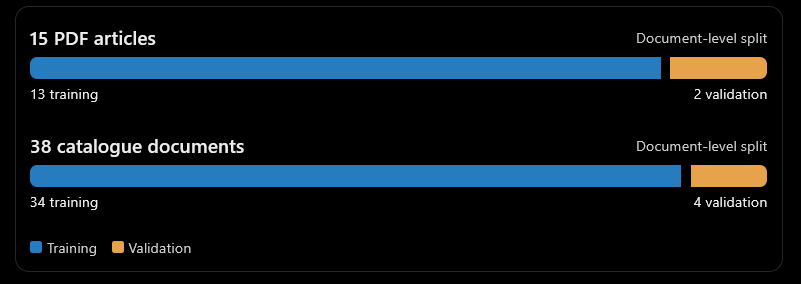

In [9]:
#-----------[TRAIN / VALIDATION SPLIT]-----------

def split_documents(docs, seed):
    shuffled = docs.copy()
    random.Random(seed).shuffle(shuffled)

    n_val = max(1, round(len(shuffled) * 0.10))

    return shuffled[n_val:], shuffled[:n_val]


#Split articles
train_article_docs, val_article_docs = split_documents(
    article_docs, SEED
)

#Split catalogue
train_catalog_docs, val_catalog_docs = split_documents(
    catalog_docs, SEED + 1
)

#Combine documents for CPT
train_docs = train_article_docs + train_catalog_docs
val_docs = val_article_docs + val_catalog_docs

#Keep product records for later SFT
train_products = [
    product
    for doc in train_catalog_docs
    for product in doc["products"]
]

val_products = [
    product
    for doc in val_catalog_docs
    for product in doc["products"]
]

# Save JSONL helper for later steps
def write_jsonl(path, records):
    with open(path, "w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")


# Results
print(f"Articles: {len(train_article_docs)} train / {len(val_article_docs)} validation")
print(f"Catalogue: {len(train_catalog_docs)} train / {len(val_catalog_docs)} validation")
print(f"Total documents: {len(train_docs)} train / {len(val_docs)} validation")
print(f"Products: {len(train_products)} train / {len(val_products)} validation")

Articles: 13 train / 1 validation
Catalogue: 34 train / 4 validation
Total documents: 47 train / 5 validation
Products: 2005 train / 240 validation


## 8. Load tokenizer and prepare fixed-length next-token sequences
Model choice is set in **one** configuration cell. We use the model's existing EOS as the padding token where a separate padding token is absent. Small incomplete remainders are not mixed between train and held-out sets.

In [10]:
#-----------[LOAD TOKENIZER & BASE MODEL]-----------

from transformers import AutoTokenizer, AutoModelForCausalLM
from torch.utils.data import Dataset

#Select device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

#GPT-2 has no default padding token
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

#Load pretrained model
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
base_model.config.pad_token_id = tokenizer.pad_token_id
base_model.to(DEVICE)

print("Model:", MODEL_NAME)
print("Device:", DEVICE)
print("Parameters:", sum(p.numel() for p in base_model.parameters()))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Model: gpt2
Device: cuda
Parameters: 124439808


In [11]:
#-----------[PACK DOCUMENTS FOR CPT]-----------

#Converts docs into token IDs and then puts them in one stream
#That stream is then divided by BLOCK_SIZE in config cell
def pack_documents(documents, tokenizer, block_size):
    tokens = []

    for doc in documents:
        ids = tokenizer(
            doc["text"],
            add_special_tokens=False
        )["input_ids"]

        tokens.extend(ids)
        tokens.append(tokenizer.eos_token_id)

    blocks = [
        tokens[i:i + block_size]
        for i in range(0, len(tokens) - block_size + 1, block_size)
    ]

    return blocks, len(tokens)















class CPTDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = blocks

    def __len__(self):
        return len(self.blocks)

    def __getitem__(self, idx):
        tokens = torch.tensor(self.blocks[idx], dtype=torch.long)

        return {
            "input_ids": tokens,
            "attention_mask": torch.ones_like(tokens),
            "labels": tokens.clone()
        }


# Tokenize and pack training and validation documents
train_blocks, train_token_count = pack_documents(
    train_docs, tokenizer, BLOCK_SIZE
)

heldout_blocks, heldout_token_count = pack_documents(
    val_docs, tokenizer, BLOCK_SIZE
)



#Create PyTorch datasets
cpt_train_ds = CPTDataset(train_blocks)
cpt_val_ds = CPTDataset(heldout_blocks)

print("Training tokens:", train_token_count)
print("Validation tokens:", heldout_token_count)
print("Training sequences:", len(cpt_train_ds))
print("Validation sequences:", len(cpt_val_ds))

Token indices sequence length is longer than the specified maximum sequence length for this model (9675 > 1024). Running this sequence through the model will result in indexing errors


Training tokens: 176091
Validation tokens: 24656
Training sequences: 343
Validation sequences: 48


## 9. Base-model checkpoint: perplexity and five original prompts
Use the **same five continuation prompts** before and after CPT. Perplexity uses the held-out sequence blocks; it is not a compatibility-accuracy score.

In [12]:
#-----------[BASE MODEL EVALUATION]-----------

from torch.utils.data import DataLoader


#Calculate loss and perplexity on held-out data
@torch.no_grad()
def evaluate_cpt_perplexity(model, dataset, batch_size=EVAL_BATCH_SIZE):
    model.eval()

    loader = DataLoader(dataset, batch_size=batch_size)

    total_loss = 0
    total_tokens = 0

    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}

        loss = model(**batch).loss

        # Causal LM predicts all tokens except the first one
        n_tokens = (batch["labels"][:, 1:] != -100).sum().item()

        total_loss += loss.item() * n_tokens
        total_tokens += n_tokens

    avg_loss = total_loss / total_tokens

    return {
        "loss": avg_loss,
        "perplexity": math.exp(avg_loss)
    }


# Generate text from a prompt
@torch.no_grad()
def complete_prompt(model, tok, prompt, chat=False,
                    max_new_tokens=GEN_MAX_NEW_TOKENS):

    model.eval()

    # SFT will use our chat format later
    if chat:
        prompt = f"<|user|>\n{prompt}\n<|assistant|>\n"

    inputs = tok(prompt, return_tensors="pt").to(DEVICE)

    # Stop at the SFT end marker when using chat format
    end_token = tok.convert_tokens_to_ids("<|end|>") if chat else tok.eos_token_id
    if end_token is None or end_token == tok.unk_token_id:
        end_token = tok.eos_token_id

    outputs = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        eos_token_id=end_token,
        pad_token_id=tok.pad_token_id
    )

    # Return only newly generated text, not the original prompt
    generated = outputs[0, inputs["input_ids"].shape[1]:]

    return tok.decode(generated, skip_special_tokens=True).strip()


# Five prompts to compare before and after CPT
CONTINUATION_PROMPTS = [
    "CPU and motherboard compatibility depends on",
    "DDR4 and DDR5 memory are different because",
    "When choosing a power supply for a gaming PC,",
    "A PC case must support the motherboard",
    "Before assembling a computer, it is important to"
]


# Evaluate the original model
base_metrics = evaluate_cpt_perplexity(base_model, cpt_val_ds)

print("Base model loss:", round(base_metrics["loss"], 4))
print("Base model perplexity:", round(base_metrics["perplexity"], 4))


# Generate and save baseline completions
base_continuations = [
    complete_prompt(base_model, tokenizer, prompt)
    for prompt in CONTINUATION_PROMPTS
]

# Display results
baseline_results = pd.DataFrame({
    "Prompt": CONTINUATION_PROMPTS,
    "Base Response": base_continuations
})

display(baseline_results)

# Save for later comparison
baseline_results.to_csv(
    OUTPUT_DIR / "base_continuations.csv",
    index=False
)

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Base model loss: 3.9107
Base model perplexity: 49.9355


,Prompt,Base Response
0,CPU and motherboard compatibility depends on,the motherboard.\n\nThe following table lists ...
1,DDR4 and DDR5 memory are different because,they are different in that they are different ...
2,"When choosing a power supply for a gaming PC,",you should consider the following factors:\n\n...
3,A PC case must support the motherboard,"'s operating system, and the motherboard must ..."
4,"Before assembling a computer, it is important to",understand the basic concepts of the computer....


## 10. Continued pretraining — next-token prediction
Uses the course's suggested learning rate, 512-token blocks, document-held-out validation, and 1–3 epochs. The best validation checkpoint is restored automatically. All settings remain in the configuration cell.

In [13]:
#-----------[CONTINUED PRETRAINING]-----------

from transformers import Trainer, TrainingArguments


# Automatically select mixed precision when a supported GPU is available
AMP_BF16 = DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()
AMP_FP16 = DEVICE.type == "cuda" and not AMP_BF16


# Training configuration
cpt_args = TrainingArguments(

    # Where to save training checkpoints
    output_dir=str(OUTPUT_DIR / "cpt_checkpoints"),

    # Training hyperparameters from Step 2
    num_train_epochs=CPT_EPOCHS,
    max_steps=MAX_TRAIN_STEPS,
    learning_rate=CPT_LR,

    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,

    # Log training loss every 10 optimizer steps
    logging_steps=10,

    # Evaluate and save after each epoch
    eval_strategy="epoch",
    save_strategy="epoch",

    # Keep the checkpoint with the lowest validation loss
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    save_total_limit=3,

    # GPU precision
    bf16=AMP_BF16,
    fp16=AMP_FP16,

    # Reproducibility
    seed=SEED,

    # Disable external experiment tracking
    report_to="none"
)


# Disable generation caching during training
base_model.config.use_cache = False


# Create the trainer
cpt_trainer = Trainer(
    model=base_model,
    args=cpt_args,
    train_dataset=cpt_train_ds,
    eval_dataset=cpt_val_ds,
    processing_class=tokenizer
)


# Start continued pretraining
cpt_trainer.train()


# Restore generation caching
base_model.config.use_cache = True


# Save the trained model and tokenizer
CPT_MODEL_PATH = OUTPUT_DIR / "cpt_model"

cpt_trainer.save_model(str(CPT_MODEL_PATH))
tokenizer.save_pretrained(str(CPT_MODEL_PATH))


# Save training history for later plotting
cpt_history = cpt_trainer.state.log_history

with open(OUTPUT_DIR / "cpt_history.json", "w") as f:
    json.dump(cpt_history, f, indent=2)


print("CPT complete.")
print("Model saved to:", CPT_MODEL_PATH)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 50256}.


Epoch,Training Loss,Validation Loss
1,2.685800,2.702532
2,2.405600,2.615800


There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


CPT complete.
Model saved to: /content/Jordanian-PC-Builder---DS493/results/cpt_model


## 11. Inspect CPT results and compare the original five prompts

Base perplexity: 49.936
CPT perplexity: 13.748


,Prompt,Base Model,After CPT
0,CPU and motherboard compatibility depends on,the motherboard.\n\nThe following table lists ...,the motherboard.\n\nHow to Choose the Right Mo...
1,DDR4 and DDR5 memory are different because,they are different in that they are different ...,they are the same type of memory.\n\nThe DDR5 ...
2,"When choosing a power supply for a gaming PC,",you should consider the following factors:\n\n...,it's important to consider the power supply's ...
3,A PC case must support the motherboard,"'s operating system, and the motherboard must ...",", motherboard, and USB 3.2 Gen2 Type-C ports.\..."
4,"Before assembling a computer, it is important to",understand the basic concepts of the computer....,"know the operating system, the operating syste..."


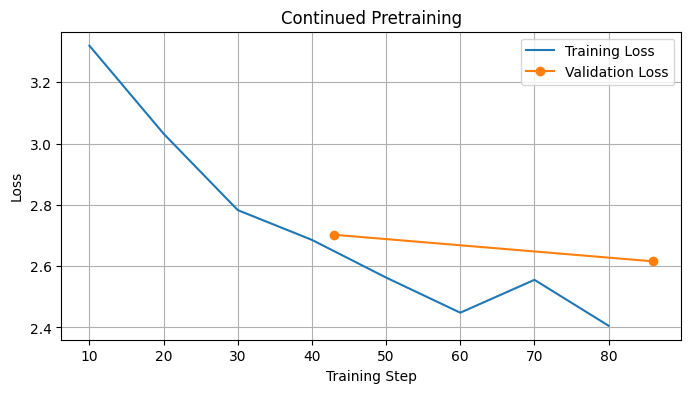

In [14]:
#-----------[EVALUATE CPT RESULTS]-----------

# 1. Evaluate perplexity after training
cpt_metrics = evaluate_cpt_perplexity(base_model, cpt_val_ds)

print("Base perplexity:", round(base_metrics["perplexity"], 3))
print("CPT perplexity:", round(cpt_metrics["perplexity"], 3))


# 2. Generate responses using the CPT model
cpt_continuations = [
    complete_prompt(base_model, tokenizer, prompt)
    for prompt in CONTINUATION_PROMPTS
]

# Compare responses before and after training
comparison = pd.DataFrame({
    "Prompt": CONTINUATION_PROMPTS,
    "Base Model": base_continuations,
    "After CPT": cpt_continuations
})

display(comparison)

# Save comparison
comparison.to_csv(
    OUTPUT_DIR / "cpt_comparison.csv",
    index=False
)


# 3. Plot training and validation loss
history = pd.DataFrame(cpt_history)

train_history = history.dropna(subset=["loss"])
val_history = history.dropna(subset=["eval_loss"])

plt.figure(figsize=(8, 4))

plt.plot(
    train_history["step"],
    train_history["loss"],
    label="Training Loss"
)

plt.plot(
    val_history["step"],
    val_history["eval_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Continued Pretraining")
plt.legend()
plt.grid(True)

# Save graph for Phase 2 report
plt.savefig(
    OUTPUT_DIR / "cpt_loss.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## 12. Prepare SFT Q&A pairs (source-backed, not invented)
The **catalogue price questions** are automatically grounded in your real CSV, using only CPT-train products. Optional `sft_verified.jsonl` contributes **human-reviewed compatibility answers** from the technical articles. The notebook cannot verify article Q&As automatically.

**Phase 2 requires 300–1,000 checked pairs** and no overlap with your 30-question test set. Catalogue-generated pairs are candidates: check at least 50 manually (and verify other examples as needed) before claiming full assignment compliance. Without verified article Q&As, SFT mainly teaches *price-question formatting*, not complex compatibility guidance.

In [15]:
def normalize_question(text):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", str(text).casefold())).strip()

# Test questions are never training pairs. When present, remove product-name overlaps too.
if TEST_CSV_PATH.exists():
    official_test = pd.read_csv(TEST_CSV_PATH).fillna("")
    assert "question" in official_test.columns, "test_questions.csv must contain 'question'"
    test_questions = official_test["question"].astype(str).tolist()
    print("Official test questions loaded:", len(test_questions))
    if len(test_questions) != 30:
        print("WARNING: Phase 2 expects the same 30 Phase 1 questions.")
else:
    official_test = None
    test_questions = []
    print("WARNING: official test_questions.csv missing; cannot certify no test-set leakage.")

# A short set of demo-only prompts, also excluded from SFT.
DEMO_COMPATIBILITY_QUESTIONS = [
    "How can I tell whether a CPU and motherboard use the same socket?",
    "What should I check before buying a PSU for a gaming PC?",
    "How can I check whether a GPU physically fits inside a PC case?"
]
prohibited_questions = test_questions + DEMO_COMPATIBILITY_QUESTIONS
prohibited_normalized = [normalize_question(q) for q in prohibited_questions]

from difflib import SequenceMatcher

def too_close_to_tests(question, product_name=""):
    qn = normalize_question(question)
    pn = normalize_question(product_name)
    for tn in prohibited_normalized:
        if not tn: continue
        if qn == tn or SequenceMatcher(None, qn, tn).ratio() >= 0.84:
            return True
        # A test about a specific product is reserved, even if phrased differently.
        if pn and len(pn) >= 12 and pn in tn:
            return True
    return False

rng = random.Random(SEED)
product_pool = train_products.copy()
rng.shuffle(product_pool)
sft_pairs = []
for row in product_pool:
    q = f"At {row['store']}, what is the listed price in JOD of {row['product_name']}?"
    if too_close_to_tests(q, row["product_name"]):
        continue
    date = str(row.get("collected_at_utc", "unknown"))[:10]
    a = (f"{row['store']} listed {row['product_name']} for "
         f"{float(row['price_jod']):.2f} JOD on {date}. "
         f"Source: {row['product_url']}")
    sft_pairs.append({"question":q, "answer":a, "source":row["product_url"], "type":"catalog_price"})
    if len(sft_pairs) >= SFT_TARGET_CATALOG_PAIRS:
        break

if VERIFIED_QA_PATH.exists():
    with VERIFIED_QA_PATH.open(encoding="utf-8") as f:
        for line_no, line in enumerate(f, 1):
            if not line.strip(): continue
            obj = json.loads(line)
            assert obj.get("question") and obj.get("answer"), f"Bad verified Q&A line {line_no}"
            if too_close_to_tests(obj["question"]):
                print("Skipped near-test verified question:", obj["question"][:75]); continue
            sft_pairs.append({"question":str(obj["question"]), "answer":str(obj["answer"]),
                              "source":str(obj.get("source", "verified_by_team")), "type":"article_verified"})
else:
    print("No sft_verified.jsonl supplied. Add reviewed article-based Q&As for compatibility coverage.")

seen = set(); deduped = []
for pair in sft_pairs:
    key = normalize_question(pair["question"])
    if key in seen: continue
    seen.add(key); deduped.append(pair)
sft_pairs = deduped
print("SFT candidate pairs:", len(sft_pairs), "| by type:", pd.Series([p["type"] for p in sft_pairs]).value_counts().to_dict())
if not (300 <= len(sft_pairs) <= 1000):
    print("WARNING: course recommends 300–1,000 SFT pairs; adjust target/reviewed Q&As.")
assert len(sft_pairs) >= 20, "Too few SFT pairs to train. Review the catalogue and config."
write_jsonl(OUTPUT_DIR / "sft_pairs_review_before_use.jsonl", sft_pairs)
display(pd.DataFrame(sft_pairs).head(3))

No sft_verified.jsonl supplied. Add reviewed article-based Q&As for compatibility coverage.
SFT candidate pairs: 500 | by type: {'catalog_price': 500}


,question,answer,source,type
0,"At Oriental Store, what is the listed price in...",Oriental Store listed AMD Ryzen 7 5700X Up to ...,https://os-jo.com/amd-ryzen-7-5700x-up-to-4-6-...,catalog_price
1,"At Oriental Store, what is the listed price in...",Oriental Store listed Asus Cerberus GTX 1050Ti...,https://os-jo.com/asus-cerberus-gtx-1050ti-oc-...,catalog_price
2,"At Oriental Store, what is the listed price in...",Oriental Store listed Cooler Master Standard A...,https://os-jo.com/cooler-master-standard-air-c...,catalog_price


## 13. Inspect Q&A candidates and split SFT pairs 90/10
For course submission, inspect and verify generated examples (at least 50 if LLM-generated; manual checking is still recommended for these templated examples), add some compatibility Q&As, and ensure the official 30 test questions are absent. This notebook does not fabricate approvals.

In [16]:
rng = random.Random(SEED + 3)
sft_shuffled = sft_pairs.copy(); rng.shuffle(sft_shuffled)
val_n = max(1, round(len(sft_shuffled) * 0.1))
sft_val_pairs = sft_shuffled[:val_n]
sft_train_pairs = sft_shuffled[val_n:]
assert set(normalize_question(x["question"]) for x in sft_train_pairs).isdisjoint(
       normalize_question(x["question"]) for x in sft_val_pairs)
write_jsonl(OUTPUT_DIR / "sft_train.jsonl", sft_train_pairs)
write_jsonl(OUTPUT_DIR / "sft_val.jsonl", sft_val_pairs)
print("SFT:", len(sft_train_pairs), "train;", len(sft_val_pairs), "validation")
print("Check samples before training:")
for p in sft_train_pairs[:5]:
    print("Q:", p["question"][:180], "\nA:", p["answer"][:200], "\n")

SFT: 450 train; 50 validation
Check samples before training:
Q: At Oriental Store, what is the listed price in JOD of GIGABYTE B760 AORUS ELITE, Intel 13th 12th Series, LGA 1700/DDR4/PCIe 4.0/3xM.2 - ATX Gaming MotherBoard? 
A: Oriental Store listed GIGABYTE B760 AORUS ELITE, Intel 13th 12th Series, LGA 1700/DDR4/PCIe 4.0/3xM.2 - ATX Gaming MotherBoard for 159.00 JOD on 2026-10-31. Source: https://os-jo.com/gigabyte-b760-aor 

Q: At Oriental Store, what is the listed price in JOD of Thermal Grizzly MINUS PAD 8 - 100X 100X 1,0 MM? 
A: Oriental Store listed Thermal Grizzly MINUS PAD 8 - 100X 100X 1,0 MM for 25.00 JOD on 2026-10-31. Source: https://os-jo.com/thermal-grizzly-minus-pad-8-100x-100x-1-0-mm 

Q: At Oriental Store, what is the listed price in JOD of GIGABYTE H610M K, Intel 14th 13th 12th Series, LGA 1700/DDR4/PCIe 4.0/1xM.2 - mATX MotherBoard? 
A: Oriental Store listed GIGABYTE H610M K, Intel 14th 13th 12th Series, LGA 1700/DDR4/PCIe 4.0/1xM.2 - mATX MotherBoard for 69.00 JOD o

## 14. Define model-independent SFT chat format with **answer-only** loss
GPT-2 does not have a standard chat format. To support both GPT-2 and other causal LMs consistently, we add three explicit markers and mask question/prompt tokens with `-100` in the training labels. **Only the answer and end marker contribute to SFT loss**.

This is deliberately implemented with `Trainer` rather than version-sensitive SFT trainer options.

In [17]:
CHAT_MARKERS = ["<|user|>", "<|assistant|>", "<|end|>"]
tokenizer.add_special_tokens({"additional_special_tokens": CHAT_MARKERS})
base_model.resize_token_embeddings(len(tokenizer))
base_model.config.pad_token_id = tokenizer.pad_token_id

def encode_sft_pair(pair, tok, max_len):
    prompt = f"<|user|>\n{pair['question']}\n<|assistant|>\n"
    answer = f"{pair['answer']}<|end|>"
    p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
    a_ids = tok(answer, add_special_tokens=False)["input_ids"]
    # Never truncate an answer invisibly: drop too-long examples and review separately.
    if not a_ids or len(p_ids) + len(a_ids) > max_len:
        return None
    return {"input_ids":p_ids+a_ids,
            "attention_mask":[1]*(len(p_ids)+len(a_ids)),
            "labels":[-100]*len(p_ids)+a_ids}

class SFTDataset(Dataset):
    def __init__(self, pairs, tok, max_len):
        self.samples = [x for p in pairs if (x:=encode_sft_pair(p,tok,max_len)) is not None]
    def __len__(self): return len(self.samples)
    def __getitem__(self, i): return self.samples[i]

class SFTCollator:
    def __init__(self, pad_id): self.pad_id = pad_id
    def __call__(self, features):
        length = max(len(x["input_ids"]) for x in features)
        result = {"input_ids":[], "attention_mask":[], "labels":[]}
        for x in features:
            n = length - len(x["input_ids"])
            result["input_ids"].append(x["input_ids"]+[self.pad_id]*n)
            result["attention_mask"].append(x["attention_mask"]+[0]*n)
            result["labels"].append(x["labels"]+[-100]*n)
        return {k:torch.tensor(v,dtype=torch.long) for k,v in result.items()}

sft_train_ds = SFTDataset(sft_train_pairs, tokenizer, SFT_MAX_LENGTH)
sft_val_ds = SFTDataset(sft_val_pairs, tokenizer, SFT_MAX_LENGTH)
print("Tokenized SFT:", len(sft_train_ds), "train /", len(sft_val_ds), "validation")
assert len(sft_train_ds) > 0 and len(sft_val_ds) > 0, "SFT samples exceed SFT_MAX_LENGTH; increase it."
example = sft_train_ds[0]
first_answer = next(i for i, label in enumerate(example["labels"]) if label != -100)
assert all(x == -100 for x in example["labels"][:first_answer])
assert all(x != -100 for x in example["labels"][first_answer:])
print("Masked question tokens:", first_answer, "| supervised answer tokens:", len(example["labels"])-first_answer)
print("First answer preview:", tokenizer.decode(example["input_ids"][first_answer:first_answer+50], skip_special_tokens=True))

The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Tokenized SFT: 450 train / 50 validation
Masked question tokens: 65 | supervised answer tokens: 129
First answer preview: Oriental Store listed GIGABYTE B760 AORUS ELITE, Intel 13th 12th Series, LGA 1700/DDR4/PCIe 4.0/3xM.2 - ATX Gaming Mother


## 15. Supervised fine-tuning (SFT)
Starts from the model just continued-pretrained, not from a fresh base model. Saves independent checkpoints and an SFT final model. Change **MODEL_NAME** at the top to switch models; no GPT-2-specific code is used.

In [18]:
sft_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "sft_checkpoints"),
    num_train_epochs=SFT_EPOCHS,
    max_steps=MAX_TRAIN_STEPS,
    learning_rate=SFT_LR,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,
    logging_strategy="steps", logging_steps=10,
    eval_strategy="epoch", save_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
    save_total_limit=3, report_to="none", seed=SEED,
    bf16=AMP_BF16, fp16=AMP_FP16, optim="adamw_torch"
)
base_model.config.use_cache = False
sft_trainer = Trainer(
    model=base_model, args=sft_args,
    train_dataset=sft_train_ds, eval_dataset=sft_val_ds,
    data_collator=SFTCollator(tokenizer.pad_token_id),
    processing_class=tokenizer,
)
sft_trainer.train()
sft_trainer.save_model(str(OUTPUT_DIR / "sft_model"))
tokenizer.save_pretrained(str(OUTPUT_DIR / "sft_model"))
sft_history = sft_trainer.state.log_history
(OUTPUT_DIR / "sft_history.json").write_text(json.dumps(sft_history, indent=2),encoding="utf-8")
base_model.config.use_cache = True
print("SFT model saved:", OUTPUT_DIR / "sft_model")

Epoch,Training Loss,Validation Loss
1,0.360100,0.278188
2,0.270700,0.258269


There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


SFT model saved: /content/Jordanian-PC-Builder---DS493/results/sft_model


## 16. Inspect SFT loss curve

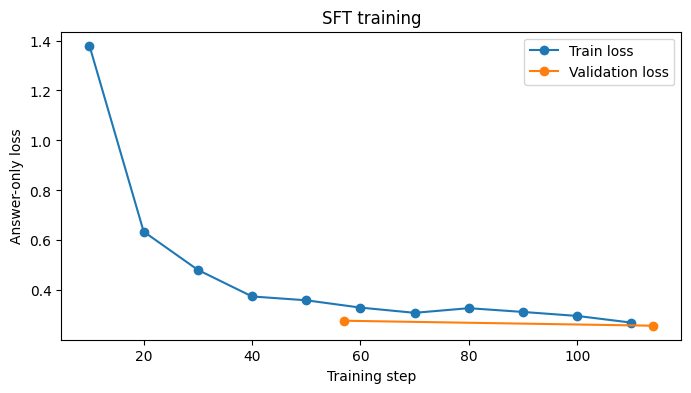

In [19]:
hist = pd.DataFrame(sft_history)
fig, ax = plt.subplots(figsize=(8, 4))
for key, label in [("loss", "Train loss"), ("eval_loss", "Validation loss")]:
    if key in hist:
        p = hist.dropna(subset=[key]); ax.plot(p["step"], p[key], marker="o", label=label)
ax.set(xlabel="Training step", ylabel="Answer-only loss", title="SFT training")
ax.legend(); plt.show()

## 17. Compare **five test questions** across base, CPT and SFT
Use the **same semantic questions** and greedy decoding for all three models. The SFT version needs its trained chat tags; the base and CPT models use a plain `Question: … Answer:` prompt. The two price examples come from **held-out catalogue records**, so their prices are source references for you, not facts these models are expected to memorize.

If you provide the Phase 1 `test_questions.csv`, the first five actual test questions are used instead of the built-in smoke tests. This section **shows examples only**; it is not the full 30-question scored evaluation required for submission.

In [20]:
if official_test is not None and len(official_test):
    prompt_questions = official_test["question"].astype(str).head(5).tolist()
    expected_answers = official_test.get("expected_answer", pd.Series([""]*len(official_test))).astype(str).head(5).tolist()
    print("Using first five official Phase 1 questions")
else:
    heldout_examples = val_products[:2]
    price_qs = [f"At {r['store']}, what is the listed price in JOD of {r['product_name']}?"
                for r in heldout_examples]
    expected_price = [f"{float(r['price_jod']):.2f} JOD (snapshot {str(r['collected_at_utc'])[:10]})"
                      for r in heldout_examples]
    prompt_questions = DEMO_COMPATIBILITY_QUESTIONS + price_qs
    expected_answers = ["Requires verification from actual compatibility articles and component specs"]*3 + expected_price
    print("No official test CSV: using five DEMO prompts, not official evaluation")
assert len(prompt_questions) == 5

# Free CUDA memory before loading each model sequentially.
del sft_trainer, cpt_trainer, base_model
gc.collect(); torch.cuda.empty_cache()

@torch.no_grad()
def predict_from_checkpoint(model_location, questions, use_chat=False):
    tok = AutoTokenizer.from_pretrained(model_location, use_fast=True)
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(model_location).to(DEVICE)
    model.config.pad_token_id = tok.pad_token_id
    predictions = [complete_prompt(model, tok, q if use_chat else f"Question: {q}\nAnswer:", chat=use_chat)
                   for q in questions]
    del model
    gc.collect(); torch.cuda.empty_cache()
    return predictions

base_answers = predict_from_checkpoint(MODEL_NAME, prompt_questions)
cpt_answers = predict_from_checkpoint(str(OUTPUT_DIR / "cpt_model"), prompt_questions)
sft_answers = predict_from_checkpoint(str(OUTPUT_DIR / "sft_model"), prompt_questions, use_chat=True)

comparison = pd.DataFrame({
    "question": prompt_questions,
    "reference_or_note": expected_answers,
    "base": base_answers,
    "after_CPT": cpt_answers,
    "after_SFT": sft_answers,
})
display(comparison)
comparison.to_csv(OUTPUT_DIR / "five_prompt_comparison.csv", index=False)
print("Saved:", OUTPUT_DIR / "five_prompt_comparison.csv")

No official test CSV: using five DEMO prompts, not official evaluation


,question,reference_or_note,base,after_CPT,after_SFT
0,How can I tell whether a CPU and motherboard u...,Requires verification from actual compatibilit...,The CPU socket is the socket that connects the...,The socket is the socket that connects the CPU...,Oriental CPU socket manufacturers are often li...
1,What should I check before buying a PSU for a ...,Requires verification from actual compatibilit...,Check the PSU's specifications before buying.\...,Check the PSU specifications before buying a P...,Oriental PSU reviews are a great way to find o...
2,How can I check whether a GPU physically fits ...,Requires verification from actual compatibilit...,The GPU is not physically inside a PC case. Th...,Check the GPU's dimensions.\nHow to Check whet...,Oriental PC case manufacturers are working on ...
3,"At Oriental Store, what is the listed price in...",129.00 JOD (snapshot 2026-10-31),The NZXT H9 Flow is a new design from the comp...,"The NZXT H9 Flow is a premium, high-performanc...",Oriental Store listed NZXT H9 Flow (2025) Pano...
4,"At Oriental Store, what is the listed price in...",229.00 JOD (snapshot 2026-10-31),The listed price is for the MSI PRO X870E-S EV...,The MSI PRO X870E-S EVO WIFI (Wi-Fi 7) AMD RYZ...,Oriental Store listed MSI PRO X870E-S EVO WIFI...


Saved: /content/Jordanian-PC-Builder---DS493/results/five_prompt_comparison.csv


## 18. Save a compact experiment record and stop
This is the end of the notebook. The complete Phase 2 scoreboard, independent grading of 30 questions, refusal accuracy, error analysis, and the final build-compatibility optimizer are **separate later steps** — not falsely presented as finished here.

In [21]:
run_summary = {
    "model": MODEL_NAME, "seed":SEED, "block_size":BLOCK_SIZE,
    "catalogue_raw_rows":int(len(raw_catalog)),
    "catalogue_usable_rows":int(len(catalog)),
    "article_count":len(article_docs),
    "cpt_train_documents":len(train_docs), "cpt_heldout_documents":len(val_docs),
    "cpt_train_tokens":train_token_count, "cpt_heldout_tokens":heldout_token_count,
    "base_heldout_perplexity":base_metrics["perplexity"],
    "cpt_heldout_perplexity":cpt_metrics["perplexity"],
    "sft_train_pairs":len(sft_train_ds), "sft_val_pairs":len(sft_val_ds),
    "official_test_csv_supplied":official_test is not None,
    "artifacts": ["cpt_model/", "sft_model/", "five_prompt_comparison.csv", "cpt_history.json", "sft_history.json"]
}
(OUTPUT_DIR / "run_summary.json").write_text(json.dumps(run_summary,indent=2), encoding="utf-8")
display(pd.Series(run_summary, name="value").to_frame())
print("Done. Everything is in:", OUTPUT_DIR)

,value
model,gpt2
seed,42
block_size,512
catalogue_raw_rows,2250
catalogue_usable_rows,2245
article_count,14
cpt_train_documents,47
cpt_heldout_documents,5
cpt_train_tokens,176091
cpt_heldout_tokens,24656


Done. Everything is in: /content/Jordanian-PC-Builder---DS493/results


In [22]:
import ipywidgets as widgets
from IPython.display import display

# Default safety state
upload_decision = False

upload_dropdown = widgets.Dropdown(
    options=[('No, do not upload', False), ('Yes, push to GitHub & Hugging Face', True)],
    value=False,
    description='Upload?:'
)

def on_upload_change(change):
    if change['type'] == 'change' and change['name'] == 'value':
        global upload_decision
        upload_decision = change['new']
        status = "WILL UPLOAD" if upload_decision else "WILL NOT UPLOAD"
        print(f"Status updated: Results {status}")

upload_dropdown.observe(on_upload_change)
display(upload_dropdown)

Dropdown(description='Upload?:', options=(('No, do not upload', False), ('Yes, push to GitHub & Hugging Face',…

Status updated: Results WILL UPLOAD


In [25]:
if upload_decision:
    print("Starting upload sequence...")

    !pip install huggingface_hub -q

    from huggingface_hub import HfApi

    hf_token_path = '/content/drive/MyDrive/Tokens/hf-token.txt'

    with open(hf_token_path, 'r') as file:
        shared_hf_token = file.read().strip()

    # 2. Initialize the Hugging Face API
    api = HfApi()

    # 3. Inject the author's name
    hf_commit_message = f"Update GPT-2 checkpoints. Uploaded by: {selected_name}"

    print(f"Uploading model weights to Hugging Face as {selected_name}...")

    # 4. Push the folder to your private Organization repository
    try:
        api.upload_folder(
            folder_path=RESULTS_PATH,
            repo_id="ds493-pc-builder/pc-builder", # Organization-Name/Model-Name
            repo_type="model",
            token=shared_hf_token,
            commit_message=hf_commit_message,
            allow_patterns=["*.safetensors", "*.bin", "*.json", "tokenizer*"]
        )
        print("Upload to Hugging Face complete!")
    except Exception as e:
        print(f"\nFailed to push to Hugging Face. Error: {e}")

    # [Paste the GitHub git.Repo code here]
    repo = git.Repo(repo_path)
    origin = repo.remotes.origin

    print("Pulling latest changes from GitHub...")
    origin.pull(rebase=True)

    print("Staging all modified and new files...")
    repo.git.add(all=True)

    if repo.is_dirty(untracked_files=True):
        # Pauses to ask for a commit message
        commit_message = input("Enter a commit message: ") or "Update RAG system files from Colab"

        # Apply the author variables chosen in Cell 2
        repo.config_writer().set_value("user", "name", selected_name).release()
        repo.config_writer().set_value("user", "email", selected_email).release()

        repo.index.commit(commit_message)
        print("Commit successful. Pushing to GitHub...")

        try:
            origin.push()
            print("Upload complete!")
        except Exception as e:
            print(f"\nFailed to push. Error: {e}")
    else:
        print("No new changes detected. Skipping commit and push.")

else:
    print("Local run complete. Upload skipped based on dropdown selection.")

Starting upload sequence...
Uploading model weights to Hugging Face as Sulieman...


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...oint-57/model.safetensors:   0%|          |  548kB /  498MB            

  ...oint-43/model.safetensors:   0%|          |  549kB /  498MB            

  ...int-114/model.safetensors:   1%|          | 3.84MB /  498MB            

... (4 outputs left out)

  ...oint-86/training_args.bin:   1%|          |  57.0B / 5.91kB            

  ...t_model/training_args.bin:   1%|          |  57.0B / 5.91kB            

  ...int-114/training_args.bin:   1%|          |  57.0B / 5.91kB            

Upload to Hugging Face complete!
Pulling latest changes from GitHub...
Staging all modified and new files...
Enter a commit message: testing upload code 
Commit successful. Pushing to GitHub...
Upload complete!


### Reference documentation

- Your supplied *Phase 2: Train a Small Model and Evaluate It*, especially pages 2–4 (CPT, SFT, 5 prompt comparisons and evaluation rules).
- [Hugging Face Transformers — Trainer](https://huggingface.co/docs/transformers/main_classes/trainer)
- [Hugging Face Transformers — Training a causal language model](https://huggingface.co/docs/transformers/tasks/language_modeling)
- [Hugging Face — SmolLM2-135M model card](https://huggingface.co/HuggingFaceTB/SmolLM2-135M)

**Notes on generality:** Any Hugging Face `AutoModelForCausalLM` model with a compatible tokenizer can be tried by editing `MODEL_NAME`. Larger models may need LoRA, quantization, or larger GPUs; this small-model notebook intentionally uses full-parameter training to match Phase 2.